In [1]:
# ==========================================================
# Cell 1 — Imports and configuration
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs

from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone

from scipy.stats import spearmanr

RANDOM_STATE = 42
EPSILON = 1e-6
N_ESTIMATORS = 300

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11

print("Notebook 4 setup complete.")

Notebook 4 setup complete.


In [2]:
# ==========================================================
# Cell 2 — Paths, output folders, and data loading
# ==========================================================

# This path works when the notebook is inside the notebooks/ folder of the project.
DATA_PATH_CANDIDATES = [
    Path("../data/raw/oedb_electrolytes_v2026_05_11.csv"),
    Path("data/raw/oedb_electrolytes_v2026_05_11.csv"),
    Path("/mnt/data/project_unzip/ML-Guided-Discovery-of-High-Performance-Electrolyte-main/data/raw/oedb_electrolytes_v2026_05_11.csv"),
    Path("/mnt/data/oedb-electrolytes-v2026-05-11 (2).csv"),
]

DATA_PATH = None
for p in DATA_PATH_CANDIDATES:
    if p.exists():
        DATA_PATH = p
        break

if DATA_PATH is None:
    raise FileNotFoundError("Could not find OEDB CSV. Check DATA_PATH_CANDIDATES.")

FIG_DIR = Path("../outputs/figures")
METRICS_DIR = Path("../outputs/metrics")
FIG_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

raw_df = pd.read_csv(DATA_PATH)

print("Data path:", DATA_PATH)
print("Raw dataset shape:", raw_df.shape)
display(raw_df.head())

Data path: ..\data\raw\oedb_electrolytes_v2026_05_11.csv
Raw dataset shape: (5616, 20)


,ID,exp-ID,Cation,Anion,Solvent,Concentration (mol/kg),Ionic Conductivity (mS/cm),Viscosity (mPa·s),Cation's Diffusivity (m²/s),Anion's Diffusivity (m²/s),Solvent's Diffusivity (m²/s),Coordination (Cation←Anion),Coordination (Cation ← Solvent),Density (g/cm³),Anion SMILES,Solvent SMILES,Anion PubChem CID,Solvent PubChem CID,x,y
0,1,NaN,K,BETI,AN,0.5,18.348073,0.320151,1.280000e-09,1.090000e-09,2.510000e-09,0.177195,6.482342,0.850743,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-60.781920,-21.211819
1,2,NaN,K,BETI,AN,1.0,40.029239,0.778737,1.230000e-09,7.410000e-10,2.110000e-09,0.332376,6.218885,0.933113,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-60.421020,-20.695742
2,3,NaN,K,BETI,AN,1.5,28.589258,0.834437,1.090000e-09,6.840000e-10,1.830000e-09,0.473627,6.034723,1.000746,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-59.876976,-19.905375
3,4,NaN,K,BETI,AN,2.0,28.614872,1.298528,7.870000e-10,5.880000e-10,1.470000e-09,0.590422,5.873371,1.066779,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-59.369880,-19.195618
4,5,NaN,K,BETI,AN,2.5,37.791487,1.086047,6.760000e-10,4.690000e-10,1.200000e-09,0.741233,5.662183,1.120867,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-58.683660,-18.369247


In [3]:
# ==========================================================
# Cell 3 — Column renaming and clean modelling table
# ==========================================================

rename_map = {
    "ID": "id",
    "exp-ID": "exp_id",
    "Cation": "cation",
    "Anion": "anion",
    "Solvent": "solvent",
    "Concentration (mol/kg)": "concentration_mol_kg",
    "Ionic Conductivity (mS/cm)": "ionic_conductivity_ms_cm",
    "Viscosity (mPa·s)": "viscosity_mpa_s",
    "Cation's Diffusivity (m²/s)": "cation_diffusivity_m2_s",
    "Anion's Diffusivity (m²/s)": "anion_diffusivity_m2_s",
    "Solvent's Diffusivity (m²/s)": "solvent_diffusivity_m2_s",
    "Coordination (Cation←Anion)": "coordination_cation_anion",
    "Coordination (Cation ← Solvent)": "coordination_cation_solvent",
    "Density (g/cm³)": "density_g_cm3",
    "Anion SMILES": "anion_smiles",
    "Solvent SMILES": "solvent_smiles",
    "Anion PubChem CID": "anion_pubchem_cid",
    "Solvent PubChem CID": "solvent_pubchem_cid",
    "x": "tsne_x",
    "y": "tsne_y",
}

df = raw_df.rename(columns=rename_map).copy()

# Conductivity is the target, so rows missing conductivity cannot be used for supervised learning.
data = df.dropna(subset=["ionic_conductivity_ms_cm"]).reset_index(drop=True).copy()
data["log_conductivity"] = np.log10(data["ionic_conductivity_ms_cm"] + EPSILON)

print("Usable modelling rows after removing missing conductivity:", data.shape[0])
print("Dropped rows:", raw_df.shape[0] - data.shape[0])
display(data.head())

Usable modelling rows after removing missing conductivity: 5595
Dropped rows: 21


,id,exp_id,cation,anion,solvent,concentration_mol_kg,ionic_conductivity_ms_cm,viscosity_mpa_s,cation_diffusivity_m2_s,anion_diffusivity_m2_s,...,coordination_cation_anion,coordination_cation_solvent,density_g_cm3,anion_smiles,solvent_smiles,anion_pubchem_cid,solvent_pubchem_cid,tsne_x,tsne_y,log_conductivity
0,1,NaN,K,BETI,AN,0.5,18.348073,0.320151,1.280000e-09,1.090000e-09,...,0.177195,6.482342,0.850743,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-60.781920,-21.211819,1.263590
1,2,NaN,K,BETI,AN,1.0,40.029239,0.778737,1.230000e-09,7.410000e-10,...,0.332376,6.218885,0.933113,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-60.421020,-20.695742,1.602377
2,3,NaN,K,BETI,AN,1.5,28.589258,0.834437,1.090000e-09,6.840000e-10,...,0.473627,6.034723,1.000746,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-59.876976,-19.905375,1.456203
3,4,NaN,K,BETI,AN,2.0,28.614872,1.298528,7.870000e-10,5.880000e-10,...,0.590422,5.873371,1.066779,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-59.369880,-19.195618,1.456592
4,5,NaN,K,BETI,AN,2.5,37.791487,1.086047,6.760000e-10,4.690000e-10,...,0.741233,5.662183,1.120867,C(C(F)(F)S(=O)(=O)[N-]S(=O)(=O)C(C(F)(F)F)(F)F...,CC#N,4067273,6342,-58.683660,-18.369247,1.577394


In [4]:
# ==========================================================
# Cell 4 — Dataset summary for presentation
# ==========================================================

summary_rows = [
    {"Item": "Total raw formulations", "Value": len(df)},
    {"Item": "Usable rows after target cleaning", "Value": len(data)},
    {"Item": "Unique cations", "Value": data["cation"].nunique()},
    {"Item": "Unique anions", "Value": data["anion"].nunique()},
    {"Item": "Unique solvents", "Value": data["solvent"].nunique()},
    {"Item": "Unique concentration levels", "Value": data["concentration_mol_kg"].nunique()},
    {"Item": "Minimum concentration (mol/kg)", "Value": data["concentration_mol_kg"].min()},
    {"Item": "Maximum concentration (mol/kg)", "Value": data["concentration_mol_kg"].max()},
]

dataset_summary = pd.DataFrame(summary_rows)
display(dataset_summary)

display(pd.DataFrame({"Cation": sorted(data["cation"].unique())}))
display(pd.DataFrame({"Anion": sorted(data["anion"].unique())}))
display(pd.DataFrame({"Solvent": sorted(data["solvent"].unique())}))

dataset_summary.to_csv(METRICS_DIR / "notebook4_dataset_summary.csv", index=False)

,Item,Value
0,Total raw formulations,5616.0
1,Usable rows after target cleaning,5595.0
2,Unique cations,3.0
3,Unique anions,9.0
4,Unique solvents,26.0
5,Unique concentration levels,8.0
6,Minimum concentration (mol/kg),0.5
7,Maximum concentration (mol/kg),4.0


,Cation
0,K
1,Li
2,Na


,Anion
0,BETI
1,BF4
2,ClO4
3,DFOB
4,FSI
5,OTf
6,PF6
7,TFA
8,TFSI


,Solvent
0,AN
1,Ac
2,Ac2O
3,BC
4,DEC
5,DMC
6,DMI
7,DMSO
8,EA
9,EB


In [5]:
# ==========================================================
# Cell 5 — Target transformation summary
# ==========================================================

# Sir asked: what transformation was applied, and what was the previous/new range?

target_transform_summary = pd.DataFrame([
    {
        "Quantity": "Ionic conductivity target",
        "Transformation": "Original/raw value",
        "Min": data["ionic_conductivity_ms_cm"].min(),
        "Max": data["ionic_conductivity_ms_cm"].max(),
        "Mean": data["ionic_conductivity_ms_cm"].mean(),
        "Std": data["ionic_conductivity_ms_cm"].std(),
    },
    {
        "Quantity": "Ionic conductivity target",
        "Transformation": "log10(value + 1e-6)",
        "Min": data["log_conductivity"].min(),
        "Max": data["log_conductivity"].max(),
        "Mean": data["log_conductivity"].mean(),
        "Std": data["log_conductivity"].std(),
    },
])

display(target_transform_summary)
target_transform_summary.to_csv(METRICS_DIR / "notebook4_target_transformation_summary.csv", index=False)

,Quantity,Transformation,Min,Max,Mean,Std
0,Ionic conductivity target,Original/raw value,0.000126,127.109335,6.135086,12.750394
1,Ionic conductivity target,log10(value + 1e-6),-3.897189,2.104177,0.126933,0.873843


In [6]:
# ==========================================================
# Cell 6 — Feature audit: chemistry-only vs physics-augmented
# ==========================================================

feature_audit = pd.DataFrame([
    {
        "Feature group": "Cation identity",
        "Status in Notebook 4": "Used in both models",
        "Reason": "Known formulation identity"
    },
    {
        "Feature group": "Anion SMILES → Morgan fingerprint + RDKit descriptors",
        "Status in Notebook 4": "Used in both models",
        "Reason": "Known molecular structure"
    },
    {
        "Feature group": "Solvent SMILES → Morgan fingerprint + RDKit descriptors",
        "Status in Notebook 4": "Used in both models",
        "Reason": "Known molecular structure"
    },
    {
        "Feature group": "Concentration",
        "Status in Notebook 4": "Used in both models",
        "Reason": "Known formulation variable"
    },
    {
        "Feature group": "Viscosity",
        "Status in Notebook 4": "Used only in physics-augmented model",
        "Reason": "Sir suggested including it because it is physically solvent-dependent"
    },
    {
        "Feature group": "Coordination numbers",
        "Status in Notebook 4": "Used only in physics-augmented model",
        "Reason": "Sir suggested including ion-solvent / ion-anion coordination information"
    },
    {
        "Feature group": "Cation/anion/solvent diffusivity",
        "Status in Notebook 4": "Still excluded from main model",
        "Reason": "Very directly related to conductivity; can inflate performance as a leakage-like transport proxy"
    },
    {
        "Feature group": "Density and t-SNE coordinates",
        "Status in Notebook 4": "Excluded",
        "Reason": "Not part of the requested update and not required for this diagnostic notebook"
    },
])

display(feature_audit)
feature_audit.to_csv(METRICS_DIR / "notebook4_feature_audit.csv", index=False)

,Feature group,Status in Notebook 4,Reason
0,Cation identity,Used in both models,Known formulation identity
1,Anion SMILES → Morgan fingerprint + RDKit desc...,Used in both models,Known molecular structure
2,Solvent SMILES → Morgan fingerprint + RDKit de...,Used in both models,Known molecular structure
3,Concentration,Used in both models,Known formulation variable
4,Viscosity,Used only in physics-augmented model,Sir suggested including it because it is physi...
5,Coordination numbers,Used only in physics-augmented model,Sir suggested including ion-solvent / ion-anio...
6,Cation/anion/solvent diffusivity,Still excluded from main model,Very directly related to conductivity; can inf...
7,Density and t-SNE coordinates,Excluded,Not part of the requested update and not requi...


In [7]:
# ==========================================================
# Cell 7 — RDKit helper functions
# ==========================================================

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)


def smiles_to_morgan_array(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")
    fp = morgan_generator.GetFingerprint(mol)
    arr = np.zeros((1024,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr


def count_atom(mol, symbol):
    return sum(1 for atom in mol.GetAtoms() if atom.GetSymbol() == symbol)


def smiles_to_descriptors(smiles):
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    return {
        "mol_wt": Descriptors.MolWt(mol),
        "exact_mol_wt": Descriptors.ExactMolWt(mol),
        "tpsa": Descriptors.TPSA(mol),
        "num_h_acceptors": Descriptors.NumHAcceptors(mol),
        "num_h_donors": Descriptors.NumHDonors(mol),
        "num_rotatable_bonds": Descriptors.NumRotatableBonds(mol),
        "ring_count": rdMolDescriptors.CalcNumRings(mol),
        "heavy_atom_count": Descriptors.HeavyAtomCount(mol),
        "num_hetero_atoms": rdMolDescriptors.CalcNumHeteroatoms(mol),
        "formal_charge": Chem.GetFormalCharge(mol),
        "num_f_atoms": count_atom(mol, "F"),
        "num_o_atoms": count_atom(mol, "O"),
        "num_n_atoms": count_atom(mol, "N"),
        "num_s_atoms": count_atom(mol, "S"),
    }


def solvent_family_from_smiles(smiles):
    """Classify solvent family using atoms present in solvent SMILES."""
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return "Unknown"
    atoms = {atom.GetSymbol() for atom in mol.GetAtoms()}

    has_o = "O" in atoms
    has_n = "N" in atoms

    if has_o and has_n:
        return "O+N-based"
    if has_o:
        return "O-based"
    if has_n:
        return "N-based"
    return "Other"

print("RDKit feature helper functions ready.")

RDKit feature helper functions ready.


In [8]:
# ==========================================================
# Cell 8 — Molecular fingerprints, descriptors, and solvent family labels
# ==========================================================

anion_fps = np.vstack(data["anion_smiles"].apply(smiles_to_morgan_array).values)
solvent_fps = np.vstack(data["solvent_smiles"].apply(smiles_to_morgan_array).values)

anion_desc = pd.DataFrame(
    data["anion_smiles"].apply(smiles_to_descriptors).tolist()
).add_prefix("anion_")

solvent_desc = pd.DataFrame(
    data["solvent_smiles"].apply(smiles_to_descriptors).tolist()
).add_prefix("solvent_")

cation_onehot = pd.get_dummies(data["cation"], prefix="cation").astype(int).reset_index(drop=True)

data["solvent_family"] = data["solvent_smiles"].apply(solvent_family_from_smiles)

solvent_family_table = (
    data[["solvent", "solvent_smiles", "solvent_family"]]
    .drop_duplicates()
    .sort_values(["solvent_family", "solvent"])
    .reset_index(drop=True)
)

display(solvent_family_table)

print("Anion fingerprint matrix:", anion_fps.shape)
print("Solvent fingerprint matrix:", solvent_fps.shape)
print("Anion descriptor matrix:", anion_desc.shape)
print("Solvent descriptor matrix:", solvent_desc.shape)
print("Cation one-hot matrix:", cation_onehot.shape)

solvent_family_table.to_csv(METRICS_DIR / "notebook4_solvent_family_table.csv", index=False)

,solvent,solvent_smiles,solvent_family
0,AN,CC#N,N-based
1,FAN,C(C#N)F,N-based
2,GN,C(CC#N)CC#N,N-based
3,SN,C(CC#N)C#N,N-based
4,DMI,CN1CCN(C1=O)C,O+N-based
5,Ac,CC(=O)C,O-based
6,Ac2O,CC(=O)OC(=O)C,O-based
7,BC,C[C@H]1[C@@H](OC(=O)O1)C,O-based
8,DEC,CCOC(=O)OCC,O-based
9,DMC,COC(=O)OC,O-based


Anion fingerprint matrix: (5595, 1024)
Solvent fingerprint matrix: (5595, 1024)
Anion descriptor matrix: (5595, 14)
Solvent descriptor matrix: (5595, 14)
Cation one-hot matrix: (5595, 3)


In [9]:
# ==========================================================
# Cell 9 — Build raw feature matrices for both model settings
# ==========================================================

chem_continuous_features = pd.concat([
    data[["concentration_mol_kg"]].reset_index(drop=True),
    anion_desc.reset_index(drop=True),
    solvent_desc.reset_index(drop=True),
], axis=1)

physics_extra_features = data[[
    "viscosity_mpa_s",
    "coordination_cation_anion",
    "coordination_cation_solvent",
]].reset_index(drop=True)

physics_continuous_features = pd.concat([
    chem_continuous_features.reset_index(drop=True),
    physics_extra_features.reset_index(drop=True),
], axis=1)


def build_feature_set(continuous_df, feature_set_name):
    """Build raw matrix. Fingerprints and cation one-hot stay binary; continuous columns are scaled inside each split."""
    X_raw = np.hstack([
        anion_fps,
        solvent_fps,
        cation_onehot.values,
        continuous_df.values,
    ]).astype(np.float32)

    feature_names = (
        [f"anion_fp_{i}" for i in range(anion_fps.shape[1])] +
        [f"solvent_fp_{i}" for i in range(solvent_fps.shape[1])] +
        list(cation_onehot.columns) +
        list(continuous_df.columns)
    )

    # Continuous features start after anion fp + solvent fp + cation one-hot.
    continuous_start = anion_fps.shape[1] + solvent_fps.shape[1] + cation_onehot.shape[1]
    scale_indices = np.arange(continuous_start, X_raw.shape[1])

    block_labels = []
    block_labels += ["anion_fingerprint"] * anion_fps.shape[1]
    block_labels += ["solvent_fingerprint"] * solvent_fps.shape[1]
    block_labels += ["cation_onehot"] * cation_onehot.shape[1]

    for col in continuous_df.columns:
        if col == "concentration_mol_kg":
            block_labels.append("concentration")
        elif col.startswith("anion_"):
            block_labels.append("anion_descriptors")
        elif col.startswith("solvent_"):
            block_labels.append("solvent_descriptors")
        elif col == "viscosity_mpa_s":
            block_labels.append("viscosity")
        elif col.startswith("coordination"):
            block_labels.append("coordination")
        else:
            block_labels.append("other_continuous")

    metadata = pd.DataFrame({
        "feature_index": np.arange(len(feature_names)),
        "feature_name": feature_names,
        "feature_block": block_labels,
        "is_scaled": [idx in set(scale_indices) for idx in range(len(feature_names))]
    })

    print(f"{feature_set_name} matrix shape:", X_raw.shape)
    print(f"Continuous scaled columns in {feature_set_name}:", len(scale_indices))

    return {
        "name": feature_set_name,
        "X_raw": X_raw,
        "continuous_df": continuous_df,
        "scale_indices": scale_indices,
        "feature_names": feature_names,
        "metadata": metadata,
    }

feature_sets = {
    "Chemistry-only scaled": build_feature_set(chem_continuous_features, "Chemistry-only scaled"),
    "Physics-augmented scaled": build_feature_set(physics_continuous_features, "Physics-augmented scaled"),
}

y_raw = data["ionic_conductivity_ms_cm"].values
# The model learns log-conductivity, and predictions are converted back to raw mS/cm for metrics.
y_log = data["log_conductivity"].values

for fs_name, fs in feature_sets.items():
    safe_name = fs_name.replace(" ", "_").lower()
    fs["metadata"].to_csv(METRICS_DIR / f"notebook4_feature_metadata_{safe_name}.csv", index=False)

Chemistry-only scaled matrix shape: (5595, 2080)
Continuous scaled columns in Chemistry-only scaled: 29
Physics-augmented scaled matrix shape: (5595, 2083)
Continuous scaled columns in Physics-augmented scaled: 32


In [10]:
# ==========================================================
# Cell 10 — Mean-centering and scaling summary
# ==========================================================

# For reporting, we show the before-scaling and after-scaling ranges.
# During validation, scaling is fitted only on the training split to avoid leakage.

scaling_summaries = []

for fs_name, fs in feature_sets.items():
    continuous_df = fs["continuous_df"]
    scaler_for_report = StandardScaler()
    scaled_values = scaler_for_report.fit_transform(continuous_df.values)
    scaled_df = pd.DataFrame(scaled_values, columns=continuous_df.columns)

    summary = pd.DataFrame({
        "Feature set": fs_name,
        "Feature": continuous_df.columns,
        "Before min": continuous_df.min().values,
        "Before max": continuous_df.max().values,
        "Before mean": continuous_df.mean().values,
        "Before std": continuous_df.std().values,
        "After min": scaled_df.min().values,
        "After max": scaled_df.max().values,
        "After mean": scaled_df.mean().values,
        "After std": scaled_df.std().values,
    })
    scaling_summaries.append(summary)

scaling_summary = pd.concat(scaling_summaries, ignore_index=True)

display(scaling_summary.head(40))
scaling_summary.to_csv(METRICS_DIR / "notebook4_scaling_before_after_summary.csv", index=False)

# A shorter view for presentation slides.
key_scaling_summary = scaling_summary[
    scaling_summary["Feature"].isin([
        "concentration_mol_kg",
        "viscosity_mpa_s",
        "coordination_cation_anion",
        "coordination_cation_solvent",
    ])
].reset_index(drop=True)

display(key_scaling_summary)
key_scaling_summary.to_csv(METRICS_DIR / "notebook4_key_scaling_summary_for_presentation.csv", index=False)

,Feature set,Feature,Before min,Before max,Before mean,Before std,After min,After max,After mean,After std
0,Chemistry-only scaled,concentration_mol_kg,0.500000,4.000000,2.253172,1.145410,-1.530743,1.525203,-2.635167e-17,1.000089
1,Chemistry-only scaled,anion_mol_wt,86.804000,380.161000,174.732553,90.482354,-0.971863,2.270573,2.997106e-16,1.000089
2,Chemistry-only scaled,anion_exact_mol_wt,87.003467,379.911455,174.624654,90.411084,-0.969229,2.270796,2.539920e-17,1.000089
3,Chemistry-only scaled,anion_tpsa,0.000000,92.240000,54.416935,33.198411,-1.639289,1.139405,-3.047904e-16,1.000089
4,Chemistry-only scaled,anion_num_h_acceptors,0.000000,4.000000,2.780697,1.618290,-1.718447,0.753519,-1.879541e-16,1.000089
5,Chemistry-only scaled,anion_num_h_donors,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000
6,Chemistry-only scaled,anion_num_rotatable_bonds,0.000000,4.000000,0.892225,1.371476,-0.650617,2.266210,2.539920e-17,1.000089
7,Chemistry-only scaled,anion_ring_count,0.000000,1.000000,0.111528,0.314813,-0.354299,2.822472,8.127745e-17,1.000089
8,Chemistry-only scaled,anion_heavy_atom_count,5.000000,21.000000,9.566935,4.929784,-0.926479,2.319389,1.422355e-16,1.000089
9,Chemistry-only scaled,anion_num_hetero_atoms,5.000000,17.000000,8.344057,3.890637,-0.859591,2.225013,5.079841e-17,1.000089


,Feature set,Feature,Before min,Before max,Before mean,Before std,After min,After max,After mean,After std
0,Chemistry-only scaled,concentration_mol_kg,0.500000,4.000000,2.253172,1.145410,-1.530743,1.525203,-2.635167e-17,1.000089
1,Physics-augmented scaled,concentration_mol_kg,0.500000,4.000000,2.253172,1.145410,-1.530743,1.525203,-2.635167e-17,1.000089
2,Physics-augmented scaled,viscosity_mpa_s,0.162418,514.916574,16.725108,33.935053,-0.488114,14.682046,-5.079841e-18,1.000089
3,Physics-augmented scaled,coordination_cation_anion,0.000109,13.798311,2.779833,2.197163,-1.265255,5.015314,-1.625549e-16,1.000089
4,Physics-augmented scaled,coordination_cation_solvent,0.232362,45.681650,5.480803,3.605031,-1.455996,11.152314,-1.422355e-16,1.000089


In [11]:
# ==========================================================
# Cell 11 — Metrics and split-safe scaling helper functions
# ==========================================================


def safe_spearman(y_true, y_pred):
    corr = spearmanr(y_true, y_pred).correlation
    if pd.isna(corr):
        return np.nan
    return corr


def top_k_metrics(y_true, y_pred, top_fraction=0.10):
    n = len(y_true)
    k = max(1, int(n * top_fraction))

    true_top_idx = set(np.argsort(y_true)[-k:])
    pred_top_idx = set(np.argsort(y_pred)[-k:])

    hits = len(true_top_idx.intersection(pred_top_idx))

    precision_at_k = hits / k
    recall_at_k = hits / k

    return precision_at_k, recall_at_k


def compute_metrics(y_true_raw, y_pred_raw):
    mae = mean_absolute_error(y_true_raw, y_pred_raw)
    rmse = np.sqrt(mean_squared_error(y_true_raw, y_pred_raw))
    r2 = r2_score(y_true_raw, y_pred_raw)
    spearman = safe_spearman(y_true_raw, y_pred_raw)
    precision_top10, recall_top10 = top_k_metrics(y_true_raw, y_pred_raw, top_fraction=0.10)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Spearman": spearman,
        "Precision@Top10%": precision_top10,
        "Recall@Top10%": recall_top10,
    }


def get_scaled_train_test(X_raw, train_idx, test_idx, scale_indices):
    """Fit StandardScaler only on the training fold, then transform train and test."""
    X_train = X_raw[train_idx].copy()
    X_test = X_raw[test_idx].copy()

    scaler = StandardScaler()
    X_train[:, scale_indices] = scaler.fit_transform(X_train[:, scale_indices])
    X_test[:, scale_indices] = scaler.transform(X_test[:, scale_indices])

    return X_train, X_test, scaler

print("Metric and scaling helper functions ready.")

Metric and scaling helper functions ready.


In [25]:
# ==========================================================
# Cell 12 — Models
# ==========================================================

models = {
    "Dummy Mean": DummyRegressor(strategy="mean"),
    "Random Forest": RandomForestRegressor(n_estimators=N_ESTIMATORS, random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=N_ESTIMATORS, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

model_run_details = pd.DataFrame([
    {
        "Model": "Dummy Mean",
        "Training detail": "Predicts mean target",
        "Equivalent iteration detail": "No trainable ensemble"
    },
    {
        "Model": "Random Forest",
        "Training detail": f"{N_ESTIMATORS} decision trees",
        "Equivalent iteration detail": f"n_estimators = {N_ESTIMATORS}"
    },
    {
        "Model": "Extra Trees",
        "Training detail": f"{N_ESTIMATORS} extremely randomized trees",
        "Equivalent iteration detail": f"n_estimators = {N_ESTIMATORS}"
    },
    {
        "Model": "Gradient Boosting",
        "Training detail": "Sequential boosting model",
        "Equivalent iteration detail": "Default n_estimators = 100 boosting stages"
    },
])

display(model_run_details)
model_run_details.to_csv(METRICS_DIR / "notebook4_model_run_details_no_epochs.csv", index=False)

,Model,Training detail,Equivalent iteration detail
0,Dummy Mean,Predicts mean target,No trainable ensemble
1,Random Forest,300 decision trees,n_estimators = 300
2,Extra Trees,300 extremely randomized trees,n_estimators = 300
3,Gradient Boosting,Sequential boosting model,Default n_estimators = 100 boosting stages


In [13]:
# ==========================================================
# Cell 13 — Evaluation functions with prediction storage
# ==========================================================


def make_prediction_frame(indices, y_true_raw, y_pred_raw, feature_set_name, validation_name, model_name, fold=None):
    pred_df = data.loc[indices, [
        "id", "cation", "anion", "solvent", "solvent_family", "concentration_mol_kg",
        "ionic_conductivity_ms_cm", "viscosity_mpa_s",
        "coordination_cation_anion", "coordination_cation_solvent"
    ]].copy()

    pred_df["Feature set"] = feature_set_name
    pred_df["Validation"] = validation_name
    pred_df["Model"] = model_name
    pred_df["Fold"] = fold
    pred_df["Actual conductivity"] = y_true_raw
    pred_df["Predicted conductivity"] = y_pred_raw
    pred_df["Residual actual_minus_pred"] = y_true_raw - y_pred_raw
    pred_df["Absolute error"] = np.abs(y_true_raw - y_pred_raw)

    return pred_df


def evaluate_random_split_for_feature_set(feature_set_name, fs, test_size=0.2):
    indices = np.arange(len(data))
    train_idx, test_idx = train_test_split(
        indices,
        test_size=test_size,
        random_state=RANDOM_STATE,
    )

    results = []
    predictions = []

    for model_name, base_model in models.items():
        model = clone(base_model)
        X_train, X_test, scaler = get_scaled_train_test(
            fs["X_raw"], train_idx, test_idx, fs["scale_indices"]
        )

        y_train_log = y_log[train_idx]
        y_test_raw = y_raw[test_idx]

        model.fit(X_train, y_train_log)
        pred_log = model.predict(X_test)
        pred_raw = (10 ** pred_log) - EPSILON

        metrics = compute_metrics(y_test_raw, pred_raw)
        metrics["Feature set"] = feature_set_name
        metrics["Validation"] = "Random split"
        metrics["Fold"] = np.nan
        metrics["Model"] = model_name
        metrics["Test groups"] = "Random 20% rows"
        results.append(metrics)

        predictions.append(make_prediction_frame(
            test_idx, y_test_raw, pred_raw, feature_set_name, "Random split", model_name
        ))

    return pd.DataFrame(results), pd.concat(predictions, ignore_index=True)


def evaluate_group_kfold_for_feature_set(feature_set_name, fs, groups, validation_name, n_splits=5, subset_indices=None):
    if subset_indices is None:
        subset_indices = np.arange(len(data))
    else:
        subset_indices = np.asarray(subset_indices)

    subset_groups = np.asarray(groups)[subset_indices]
    subset_y_raw = y_raw[subset_indices]

    gkf = GroupKFold(n_splits=n_splits)

    results = []
    predictions = []

    for model_name, base_model in models.items():
        if model_name == "Dummy Mean":
            continue

        for fold, (train_rel, test_rel) in enumerate(gkf.split(subset_indices, subset_y_raw, groups=subset_groups), start=1):
            train_idx = subset_indices[train_rel]
            test_idx = subset_indices[test_rel]

            model = clone(base_model)

            X_train, X_test, scaler = get_scaled_train_test(
                fs["X_raw"], train_idx, test_idx, fs["scale_indices"]
            )

            y_train_log = y_log[train_idx]
            y_test_raw = y_raw[test_idx]

            model.fit(X_train, y_train_log)
            pred_log = model.predict(X_test)
            pred_raw = (10 ** pred_log) - EPSILON

            metrics = compute_metrics(y_test_raw, pred_raw)
            metrics["Feature set"] = feature_set_name
            metrics["Validation"] = validation_name
            metrics["Fold"] = fold
            metrics["Model"] = model_name
            metrics["Test groups"] = ", ".join(map(str, sorted(pd.Series(groups[test_idx]).unique())))
            results.append(metrics)

            predictions.append(make_prediction_frame(
                test_idx, y_test_raw, pred_raw, feature_set_name, validation_name, model_name, fold
            ))

    return pd.DataFrame(results), pd.concat(predictions, ignore_index=True)

print("Evaluation functions ready.")

Evaluation functions ready.


In [14]:
# ==========================================================
# Cell 14 — Random split evaluation: chemistry-only vs physics-augmented
# ==========================================================

random_result_frames = []
random_prediction_frames = []

for fs_name, fs in feature_sets.items():
    res_df, pred_df = evaluate_random_split_for_feature_set(fs_name, fs)
    random_result_frames.append(res_df)
    random_prediction_frames.append(pred_df)

random_split_results_df = pd.concat(random_result_frames, ignore_index=True)
random_split_predictions_df = pd.concat(random_prediction_frames, ignore_index=True)

random_split_results_df = random_split_results_df[[
    "Feature set", "Validation", "Model", "MAE", "RMSE", "R2", "Spearman", "Precision@Top10%", "Recall@Top10%"
]]

display(random_split_results_df)

random_split_results_df.to_csv(METRICS_DIR / "notebook4_random_split_results.csv", index=False)
random_split_predictions_df.to_csv(METRICS_DIR / "notebook4_random_split_predictions.csv", index=False)

,Feature set,Validation,Model,MAE,RMSE,R2,Spearman,Precision@Top10%,Recall@Top10%
0,Chemistry-only scaled,Random split,Dummy Mean,5.517865,13.028978,-0.150007,NaN,0.081081,0.081081
1,Chemistry-only scaled,Random split,Random Forest,1.999270,5.522884,0.793361,0.962827,0.900901,0.900901
2,Chemistry-only scaled,Random split,Extra Trees,2.148332,6.116694,0.746538,0.960318,0.882883,0.882883
3,Chemistry-only scaled,Random split,Gradient Boosting,2.342154,6.015902,0.754822,0.922004,0.882883,0.882883
4,Physics-augmented scaled,Random split,Dummy Mean,5.517865,13.028978,-0.150007,NaN,0.081081,0.081081
5,Physics-augmented scaled,Random split,Random Forest,1.995885,5.489686,0.795838,0.961077,0.909910,0.909910
6,Physics-augmented scaled,Random split,Extra Trees,2.031717,5.847114,0.768387,0.964460,0.882883,0.882883
7,Physics-augmented scaled,Random split,Gradient Boosting,2.008802,5.333573,0.807285,0.955293,0.900901,0.900901


In [15]:
# ==========================================================
# Cell 15 — GroupKFold evaluation: solvent, anion, and concentration
# ==========================================================

validation_configs = [
    {
        "Validation": "Solvent GroupKFold",
        "Groups": data["solvent"].values,
        "n_splits": 5,
    },
    {
        "Validation": "Anion GroupKFold",
        "Groups": data["anion"].values,
        "n_splits": 5,
    },
    {
        "Validation": "Concentration GroupKFold",
        "Groups": data["concentration_mol_kg"].values,
        "n_splits": 4,
    },
]

group_result_frames = []
group_prediction_frames = []

for fs_name, fs in feature_sets.items():
    print("Running grouped validation for:", fs_name)
    for cfg in validation_configs:
        print("  ", cfg["Validation"])
        res_df, pred_df = evaluate_group_kfold_for_feature_set(
            feature_set_name=fs_name,
            fs=fs,
            groups=cfg["Groups"],
            validation_name=cfg["Validation"],
            n_splits=cfg["n_splits"],
        )
        group_result_frames.append(res_df)
        group_prediction_frames.append(pred_df)

all_group_results_df = pd.concat(group_result_frames, ignore_index=True)
all_group_predictions_df = pd.concat(group_prediction_frames, ignore_index=True)

display(all_group_results_df.head())

all_group_results_df.to_csv(METRICS_DIR / "notebook4_groupkfold_foldwise_results.csv", index=False)
all_group_predictions_df.to_csv(METRICS_DIR / "notebook4_groupkfold_predictions.csv", index=False)

Running grouped validation for: Chemistry-only scaled
   Solvent GroupKFold
   Anion GroupKFold
   Concentration GroupKFold
Running grouped validation for: Physics-augmented scaled
   Solvent GroupKFold
   Anion GroupKFold
   Concentration GroupKFold


,MAE,RMSE,R2,Spearman,Precision@Top10%,Recall@Top10%,Feature set,Validation,Fold,Model,Test groups
0,6.178233,12.280900,0.413713,0.706360,0.710280,0.710280,Chemistry-only scaled,Solvent GroupKFold,1,Random Forest,"Ac, Ac2O, EA, MA, TMP"
1,6.938475,12.936791,0.462328,0.473176,0.500000,0.500000,Chemistry-only scaled,Solvent GroupKFold,2,Random Forest,"AN, DMC, DMSO, EMC, GN, SN"
2,6.114973,9.982851,0.298346,0.533867,0.682243,0.682243,Chemistry-only scaled,Solvent GroupKFold,3,Random Forest,"DMI, EB, FAN, GBL, TEP"
3,1.524531,2.184469,0.435819,0.760158,0.336449,0.336449,Chemistry-only scaled,Solvent GroupKFold,4,Random Forest,"DEC, EC, FEA, FEMC, PC"
4,1.012070,1.519478,0.532557,0.807914,0.411215,0.411215,Chemistry-only scaled,Solvent GroupKFold,5,Random Forest,"BC, EP, FEC, MB, MP"


In [16]:
# ==========================================================
# Cell 16 — Summary table and physics-feature impact
# ==========================================================

all_cv_results = pd.concat([
    random_split_results_df.assign(Fold=np.nan, **{"Test groups": "Random 20% rows"}),
    all_group_results_df,
], ignore_index=True)

summary_cv = (
    all_cv_results
    .groupby(["Feature set", "Validation", "Model"])
    .agg(
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        R2_mean=("R2", "mean"),
        R2_std=("R2", "std"),
        Spearman_mean=("Spearman", "mean"),
        Spearman_std=("Spearman", "std"),
        PrecisionTop10_mean=("Precision@Top10%", "mean"),
        PrecisionTop10_std=("Precision@Top10%", "std"),
    )
    .reset_index()
)

display(summary_cv)
summary_cv.to_csv(METRICS_DIR / "notebook4_summary_results.csv", index=False)

chem = summary_cv[summary_cv["Feature set"] == "Chemistry-only scaled"].copy()
phys = summary_cv[summary_cv["Feature set"] == "Physics-augmented scaled"].copy()

feature_impact = phys.merge(
    chem,
    on=["Validation", "Model"],
    suffixes=("_physics", "_chemistry")
)

feature_impact["Delta_MAE_physics_minus_chemistry"] = feature_impact["MAE_mean_physics"] - feature_impact["MAE_mean_chemistry"]
feature_impact["Delta_R2_physics_minus_chemistry"] = feature_impact["R2_mean_physics"] - feature_impact["R2_mean_chemistry"]
feature_impact["Delta_Spearman_physics_minus_chemistry"] = feature_impact["Spearman_mean_physics"] - feature_impact["Spearman_mean_chemistry"]
feature_impact["MAE_improvement_percent"] = 100 * (
    feature_impact["MAE_mean_chemistry"] - feature_impact["MAE_mean_physics"]
) / feature_impact["MAE_mean_chemistry"]

feature_impact_view = feature_impact[[
    "Validation", "Model",
    "MAE_mean_chemistry", "MAE_mean_physics", "Delta_MAE_physics_minus_chemistry", "MAE_improvement_percent",
    "R2_mean_chemistry", "R2_mean_physics", "Delta_R2_physics_minus_chemistry",
    "Spearman_mean_chemistry", "Spearman_mean_physics", "Delta_Spearman_physics_minus_chemistry",
]].sort_values(["Validation", "MAE_improvement_percent"], ascending=[True, False])

display(feature_impact_view)
feature_impact_view.to_csv(METRICS_DIR / "notebook4_physics_feature_impact.csv", index=False)

,Feature set,Validation,Model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,Spearman_mean,Spearman_std,PrecisionTop10_mean,PrecisionTop10_std
0,Chemistry-only scaled,Anion GroupKFold,Extra Trees,3.270311,0.778163,8.293673,2.000322,0.467767,0.279923,0.873179,0.061960,0.754183,0.097882
1,Chemistry-only scaled,Anion GroupKFold,Gradient Boosting,3.207601,1.147346,7.807995,3.092913,0.580914,0.129169,0.858843,0.039040,0.765526,0.087122
2,Chemistry-only scaled,Anion GroupKFold,Random Forest,3.083772,0.916635,7.769683,2.404763,0.564177,0.153672,0.881984,0.049922,0.778429,0.105397
3,Chemistry-only scaled,Concentration GroupKFold,Extra Trees,2.216451,0.244153,6.087027,0.891312,0.764100,0.049971,0.957951,0.007304,0.888656,0.019246
4,Chemistry-only scaled,Concentration GroupKFold,Gradient Boosting,2.563060,0.326691,6.593098,1.116592,0.724869,0.055925,0.913958,0.004559,0.850964,0.020867
5,Chemistry-only scaled,Concentration GroupKFold,Random Forest,2.206583,0.254964,5.921301,0.884218,0.780044,0.019301,0.952193,0.004587,0.890468,0.007203
6,Chemistry-only scaled,Random split,Dummy Mean,5.517865,NaN,13.028978,NaN,-0.150007,NaN,NaN,NaN,0.081081,NaN
7,Chemistry-only scaled,Random split,Extra Trees,2.148332,NaN,6.116694,NaN,0.746538,NaN,0.960318,NaN,0.882883,NaN
8,Chemistry-only scaled,Random split,Gradient Boosting,2.342154,NaN,6.015902,NaN,0.754822,NaN,0.922004,NaN,0.882883,NaN
9,Chemistry-only scaled,Random split,Random Forest,1.999270,NaN,5.522884,NaN,0.793361,NaN,0.962827,NaN,0.900901,NaN


,Validation,Model,MAE_mean_chemistry,MAE_mean_physics,Delta_MAE_physics_minus_chemistry,MAE_improvement_percent,R2_mean_chemistry,R2_mean_physics,Delta_R2_physics_minus_chemistry,Spearman_mean_chemistry,Spearman_mean_physics,Delta_Spearman_physics_minus_chemistry
1,Anion GroupKFold,Gradient Boosting,3.207601,2.387392,-0.820209,25.570793,0.580914,0.747052,0.166138,0.858843,0.933987,0.075144
2,Anion GroupKFold,Random Forest,3.083772,2.440169,-0.643603,20.870647,0.564177,0.734152,0.169975,0.881984,0.935680,0.053696
0,Anion GroupKFold,Extra Trees,3.270311,2.873128,-0.397183,12.145125,0.467767,0.607723,0.139956,0.873179,0.908505,0.035326
4,Concentration GroupKFold,Gradient Boosting,2.563060,2.234602,-0.328458,12.815090,0.724869,0.771461,0.046591,0.913958,0.951637,0.037678
3,Concentration GroupKFold,Extra Trees,2.216451,2.089054,-0.127396,5.747769,0.764100,0.789896,0.025796,0.957951,0.961991,0.004039
5,Concentration GroupKFold,Random Forest,2.206583,2.151949,-0.054634,2.475975,0.780044,0.769585,-0.010459,0.952193,0.959111,0.006918
8,Random split,Gradient Boosting,2.342154,2.008802,-0.333352,14.232715,0.754822,0.807285,0.052463,0.922004,0.955293,0.033288
7,Random split,Extra Trees,2.148332,2.031717,-0.116615,5.428155,0.746538,0.768387,0.021849,0.960318,0.964460,0.004143
9,Random split,Random Forest,1.999270,1.995885,-0.003385,0.169295,0.793361,0.795838,0.002477,0.962827,0.961077,-0.001750
6,Random split,Dummy Mean,5.517865,5.517865,0.000000,0.000000,-0.150007,-0.150007,0.000000,NaN,NaN,NaN


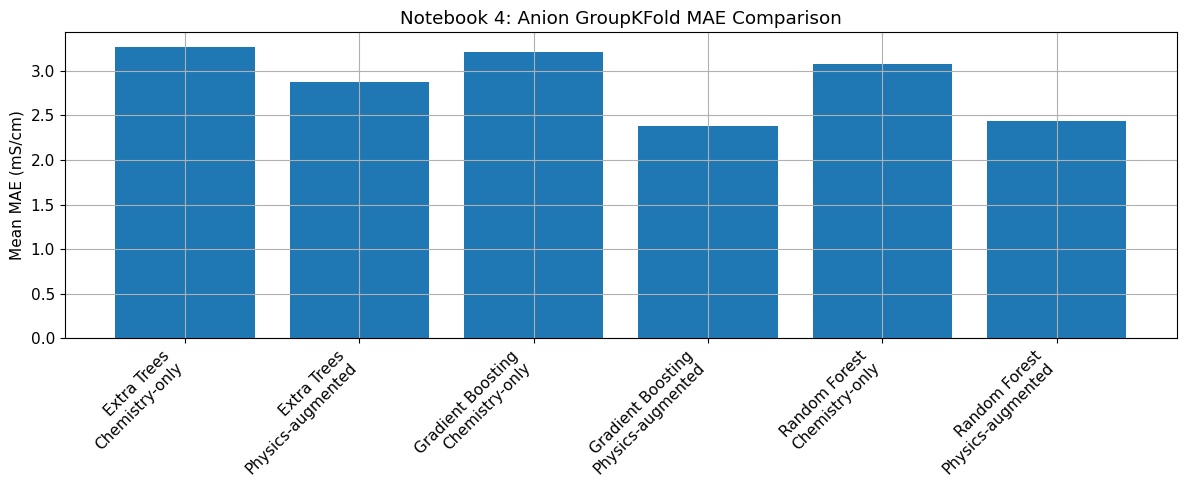

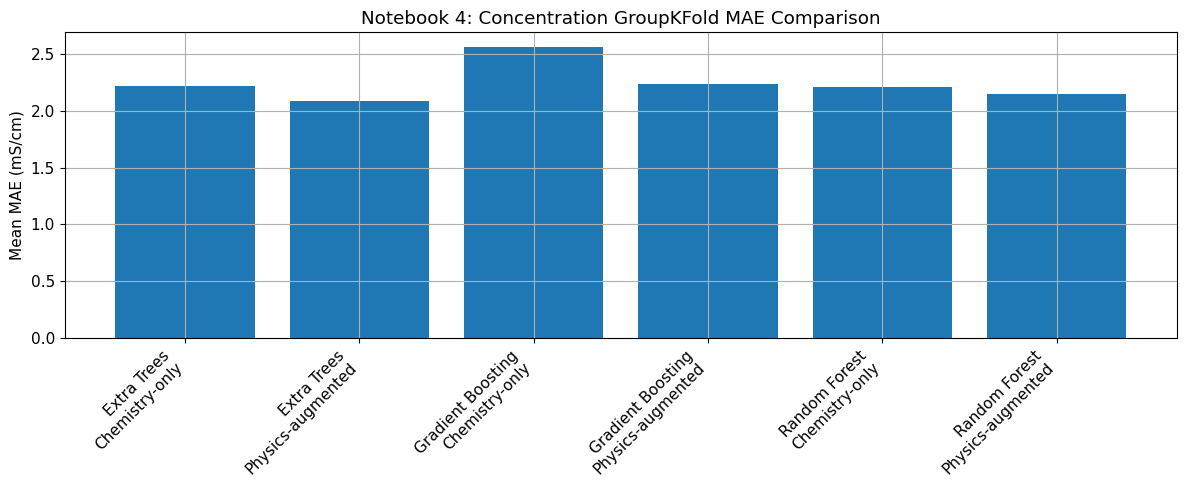

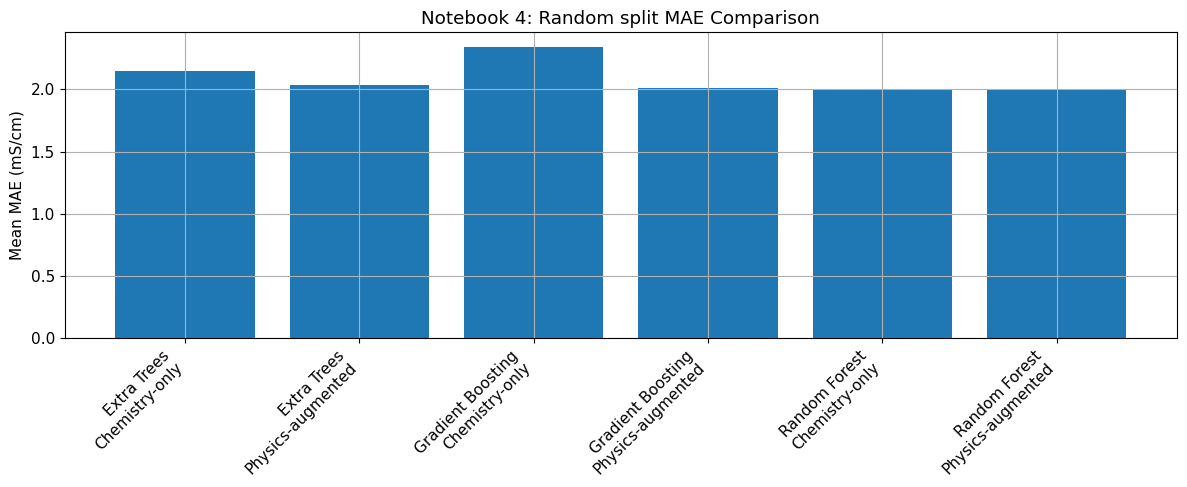

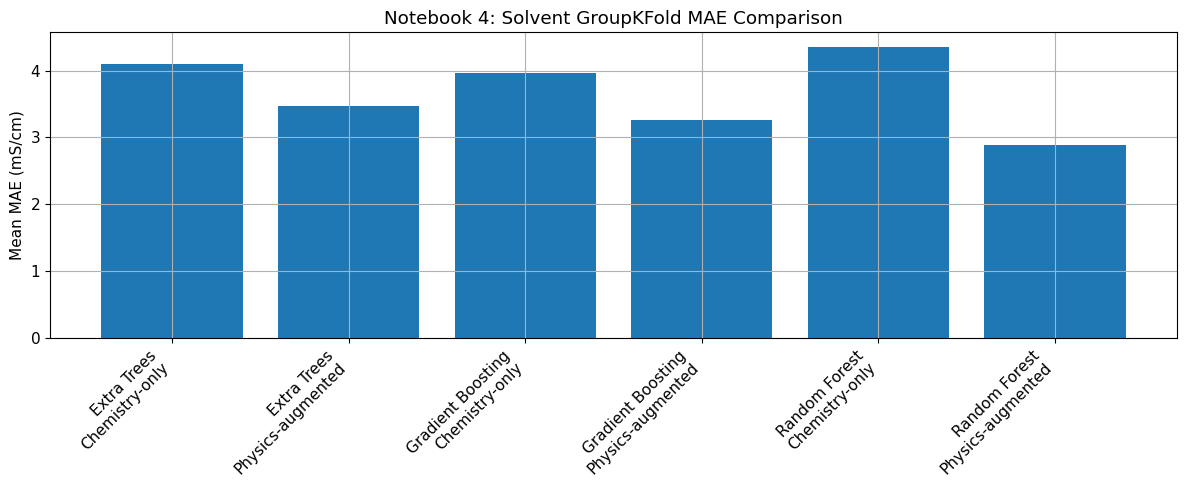

In [17]:
# ==========================================================
# Cell 17 — Plot: MAE comparison across feature sets
# ==========================================================

plot_df = summary_cv[summary_cv["Model"] != "Dummy Mean"].copy()

# Create one compact bar plot per validation type.
for validation_name in plot_df["Validation"].unique():
    subset = plot_df[plot_df["Validation"] == validation_name].copy()
    subset = subset.sort_values(["Model", "Feature set"])

    labels = subset["Model"] + "\n" + subset["Feature set"].str.replace(" scaled", "")
    x = np.arange(len(subset))

    plt.figure(figsize=(12, 5))
    plt.bar(x, subset["MAE_mean"])
    plt.xticks(x, labels, rotation=45, ha="right")
    plt.ylabel("Mean MAE (mS/cm)")
    plt.title(f"Notebook 4: {validation_name} MAE Comparison")
    plt.tight_layout()

    filename = f"notebook4_mae_{validation_name.replace(' ', '_').lower()}.png"
    plt.savefig(FIG_DIR / filename, dpi=300)
    plt.show()

In [18]:
# ==========================================================
# Cell 18 — Select best solvent-generalization setting for detailed diagnostics
# ==========================================================

# Since Notebook 3 identified solvent generalization as the main bottleneck,
# we select the best setting using Solvent GroupKFold MAE.

best_solvent_setting = (
    summary_cv[
        (summary_cv["Validation"] == "Solvent GroupKFold") &
        (summary_cv["Model"] != "Dummy Mean")
    ]
    .sort_values("MAE_mean")
    .head(1)
    .reset_index(drop=True)
)

display(best_solvent_setting)

BEST_FEATURE_SET = best_solvent_setting.loc[0, "Feature set"]
BEST_MODEL_NAME = best_solvent_setting.loc[0, "Model"]

best_solvent_predictions = all_group_predictions_df[
    (all_group_predictions_df["Feature set"] == BEST_FEATURE_SET) &
    (all_group_predictions_df["Validation"] == "Solvent GroupKFold") &
    (all_group_predictions_df["Model"] == BEST_MODEL_NAME)
].copy()

print("Best solvent diagnostic feature set:", BEST_FEATURE_SET)
print("Best solvent diagnostic model:", BEST_MODEL_NAME)
print("Prediction rows:", best_solvent_predictions.shape)

best_solvent_predictions.to_csv(METRICS_DIR / "notebook4_best_solvent_groupkfold_predictions.csv", index=False)

,Feature set,Validation,Model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,Spearman_mean,Spearman_std,PrecisionTop10_mean,PrecisionTop10_std
0,Physics-augmented scaled,Solvent GroupKFold,Random Forest,2.885294,1.522267,5.790948,3.570404,0.559195,0.241109,0.830222,0.059274,0.628198,0.237959


Best solvent diagnostic feature set: Physics-augmented scaled
Best solvent diagnostic model: Random Forest
Prediction rows: (5595, 18)


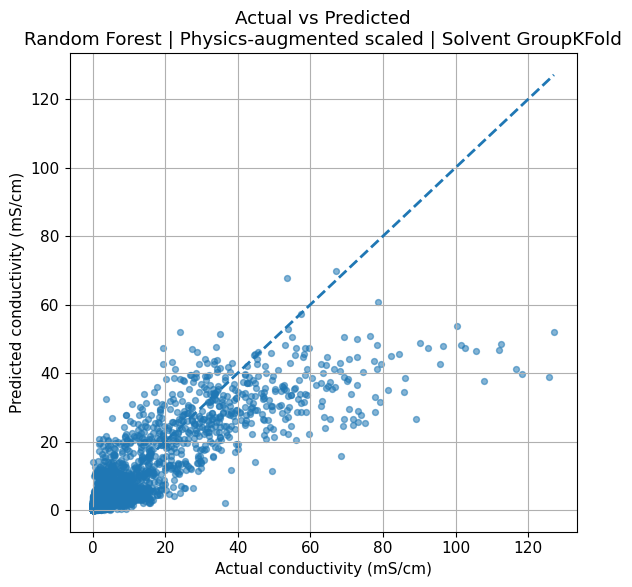

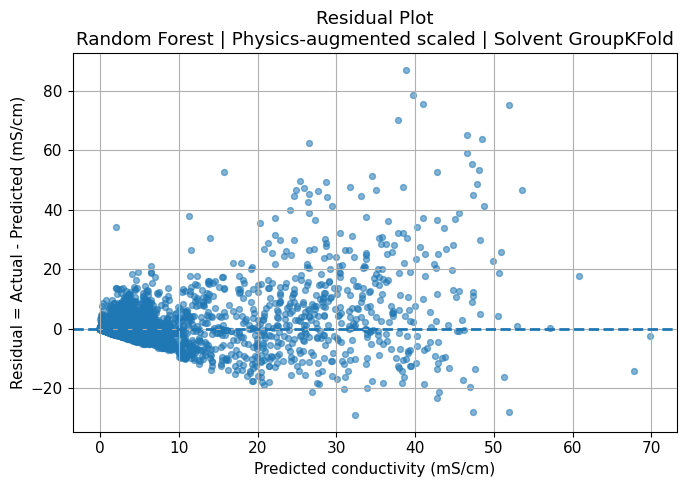

In [19]:
# ==========================================================
# Cell 19 — Actual vs Predicted plot and residual plot
# ==========================================================

actual = best_solvent_predictions["Actual conductivity"].values
predicted = best_solvent_predictions["Predicted conductivity"].values
residual = best_solvent_predictions["Residual actual_minus_pred"].values

min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())

plt.figure(figsize=(6, 6))
plt.scatter(actual, predicted, alpha=0.55, s=18)
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--", linewidth=2)
plt.xlabel("Actual conductivity (mS/cm)")
plt.ylabel("Predicted conductivity (mS/cm)")
plt.title(f"Actual vs Predicted\n{BEST_MODEL_NAME} | {BEST_FEATURE_SET} | Solvent GroupKFold")
plt.tight_layout()
plt.savefig(FIG_DIR / "notebook4_actual_vs_predicted_best_solvent_groupkfold.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(predicted, residual, alpha=0.55, s=18)
plt.axhline(0, linestyle="--", linewidth=2)
plt.xlabel("Predicted conductivity (mS/cm)")
plt.ylabel("Residual = Actual - Predicted (mS/cm)")
plt.title(f"Residual Plot\n{BEST_MODEL_NAME} | {BEST_FEATURE_SET} | Solvent GroupKFold")
plt.tight_layout()
plt.savefig(FIG_DIR / "notebook4_residual_plot_best_solvent_groupkfold.png", dpi=300)
plt.show()

,solvent,solvent_family,n_samples,MAE,RMSE,mean_actual,mean_predicted,mean_bias_actual_minus_pred
0,AN,N-based,216,13.839322,20.275410,38.445499,29.037057,9.408442
1,Ac,O-based,216,13.488129,19.630303,34.234726,22.992504,11.242222
13,FAN,N-based,216,10.110525,13.273963,20.431428,23.813066,-3.381638
7,DMSO,O-based,216,5.096910,6.972006,14.559065,11.872957,2.686108
2,Ac2O,O-based,216,4.808220,6.509551,7.881364,3.168940,4.712425
6,DMI,O+N-based,216,3.751173,4.150832,1.184645,4.933443,-3.748799
14,FEA,O-based,216,2.968777,4.254516,4.714888,1.825751,2.889137
17,GBL,O-based,216,2.866877,4.044769,6.446783,3.822253,2.624530
22,PC,O-based,216,1.985862,3.135871,1.841950,3.698601,-1.856651
19,MA,O-based,216,1.831753,2.584455,3.636793,1.900953,1.735839


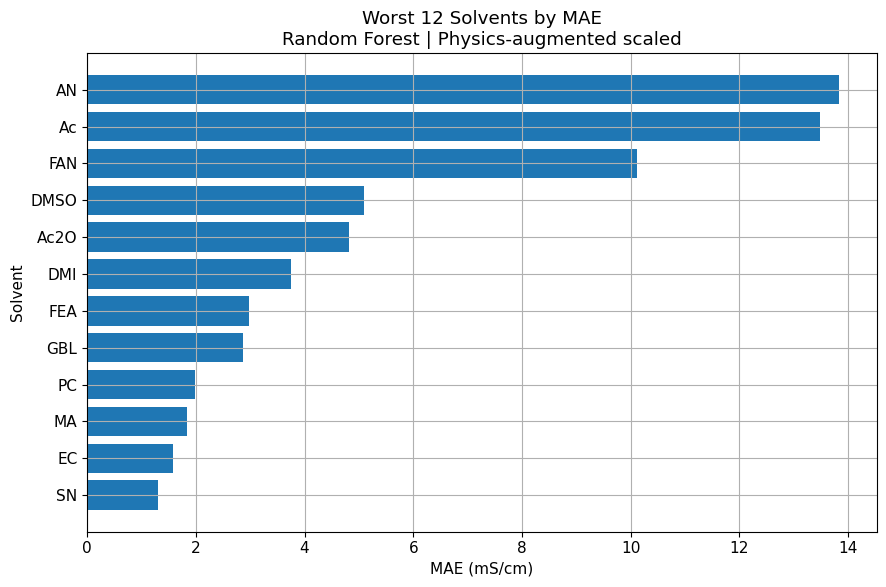

In [20]:
# ==========================================================
# Cell 20 — Solvent-wise performance analysis
# ==========================================================

solvent_error = (
    best_solvent_predictions
    .groupby(["solvent", "solvent_family"])
    .agg(
        n_samples=("Absolute error", "size"),
        MAE=("Absolute error", "mean"),
        RMSE=("Residual actual_minus_pred", lambda x: np.sqrt(np.mean(np.square(x)))),
        mean_actual=("Actual conductivity", "mean"),
        mean_predicted=("Predicted conductivity", "mean"),
        mean_bias_actual_minus_pred=("Residual actual_minus_pred", "mean"),
    )
    .reset_index()
    .sort_values("MAE", ascending=False)
)

display(solvent_error)
solvent_error.to_csv(METRICS_DIR / "notebook4_solvent_wise_error_best_model.csv", index=False)

# Worst solvents by MAE
worst_n = min(12, len(solvent_error))
worst_solvents = solvent_error.head(worst_n).sort_values("MAE")

plt.figure(figsize=(9, 6))
plt.barh(worst_solvents["solvent"], worst_solvents["MAE"])
plt.xlabel("MAE (mS/cm)")
plt.ylabel("Solvent")
plt.title(f"Worst {worst_n} Solvents by MAE\n{BEST_MODEL_NAME} | {BEST_FEATURE_SET}")
plt.tight_layout()
plt.savefig(FIG_DIR / "notebook4_worst_solvents_by_mae.png", dpi=300)
plt.show()

,solvent_family,n_samples,n_solvents,MAE,RMSE,mean_bias_actual_minus_pred
0,N-based,864,4,6.427420,12.139493,1.100258
1,O+N-based,216,1,3.751173,4.150832,-3.748799
2,O-based,4515,21,2.207970,5.175410,1.192712


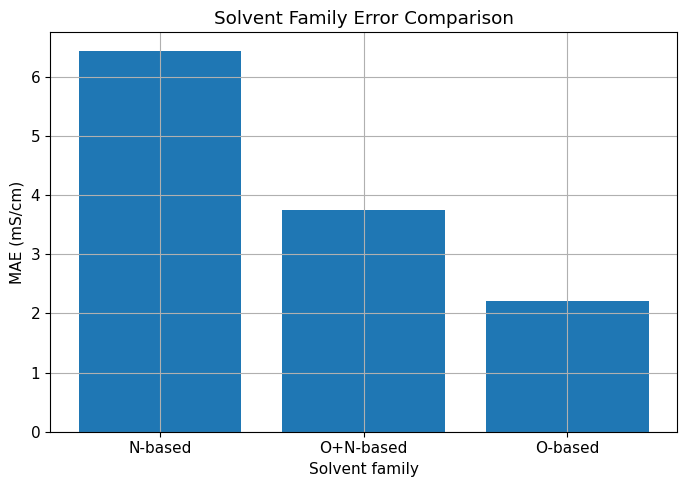

In [21]:
# ==========================================================
# Cell 21 — Solvent family performance: O-based vs N-based
# ==========================================================

family_error = (
    best_solvent_predictions
    .groupby("solvent_family")
    .agg(
        n_samples=("Absolute error", "size"),
        n_solvents=("solvent", "nunique"),
        MAE=("Absolute error", "mean"),
        RMSE=("Residual actual_minus_pred", lambda x: np.sqrt(np.mean(np.square(x)))),
        mean_bias_actual_minus_pred=("Residual actual_minus_pred", "mean"),
    )
    .reset_index()
    .sort_values("MAE", ascending=False)
)

display(family_error)
family_error.to_csv(METRICS_DIR / "notebook4_solvent_family_error_best_model.csv", index=False)

plt.figure(figsize=(7, 5))
plt.bar(family_error["solvent_family"], family_error["MAE"])
plt.ylabel("MAE (mS/cm)")
plt.xlabel("Solvent family")
plt.title("Solvent Family Error Comparison")
plt.tight_layout()
plt.savefig(FIG_DIR / "notebook4_solvent_family_mae.png", dpi=300)
plt.show()

In [22]:
# ==========================================================
# Cell 22 — Exploratory separate models for solvent families
# ==========================================================

# This is an exploratory check only. We train family-specific models if a family has enough unique solvents.
# The goal is to see whether separate O-based / N-based models are worth discussing further.

family_model_results = []
family_model_predictions = []

family_feature_set_name = "Physics-augmented scaled"
family_fs = feature_sets[family_feature_set_name]

for family in sorted(data["solvent_family"].unique()):
    subset_indices = data.index[data["solvent_family"] == family].values
    unique_solvents = data.loc[subset_indices, "solvent"].nunique()
    n_rows = len(subset_indices)

    if unique_solvents < 2 or n_rows < 50:
        print(f"Skipping {family}: not enough rows or unique solvents.")
        continue

    n_splits = min(5, unique_solvents)
    print(f"Running family-specific solvent GroupKFold for {family}: rows={n_rows}, solvents={unique_solvents}, folds={n_splits}")

    res_df, pred_df = evaluate_group_kfold_for_feature_set(
        feature_set_name=f"{family_feature_set_name} | {family} family-specific",
        fs=family_fs,
        groups=data["solvent"].values,
        validation_name="Family-specific Solvent GroupKFold",
        n_splits=n_splits,
        subset_indices=subset_indices,
    )
    res_df["Solvent family model"] = family
    pred_df["Solvent family model"] = family

    family_model_results.append(res_df)
    family_model_predictions.append(pred_df)

if family_model_results:
    family_model_results_df = pd.concat(family_model_results, ignore_index=True)
    family_model_predictions_df = pd.concat(family_model_predictions, ignore_index=True)

    family_model_summary = (
        family_model_results_df
        .groupby(["Solvent family model", "Model"])
        .agg(
            MAE_mean=("MAE", "mean"),
            MAE_std=("MAE", "std"),
            RMSE_mean=("RMSE", "mean"),
            R2_mean=("R2", "mean"),
            Spearman_mean=("Spearman", "mean"),
            PrecisionTop10_mean=("Precision@Top10%", "mean"),
        )
        .reset_index()
        .sort_values(["Solvent family model", "MAE_mean"])
    )

    display(family_model_summary)

    family_model_results_df.to_csv(METRICS_DIR / "notebook4_family_specific_foldwise_results.csv", index=False)
    family_model_predictions_df.to_csv(METRICS_DIR / "notebook4_family_specific_predictions.csv", index=False)
    family_model_summary.to_csv(METRICS_DIR / "notebook4_family_specific_summary.csv", index=False)
else:
    family_model_summary = pd.DataFrame()
    print("No family-specific models were run.")

Running family-specific solvent GroupKFold for N-based: rows=864, solvents=4, folds=4
Skipping O+N-based: not enough rows or unique solvents.
Running family-specific solvent GroupKFold for O-based: rows=4515, solvents=21, folds=5


,Solvent family model,Model,MAE_mean,MAE_std,RMSE_mean,R2_mean,Spearman_mean,PrecisionTop10_mean
1,N-based,Gradient Boosting,7.209699,8.056285,10.624474,-34.772644,0.451261,0.345238
2,N-based,Random Forest,10.159460,11.809848,14.107090,-43.710058,0.449445,0.404762
0,N-based,Extra Trees,14.911768,17.766069,18.960852,-2185.028681,0.278814,0.261905
4,O-based,Gradient Boosting,2.525805,2.535608,5.047080,0.465000,0.835305,0.514432
5,O-based,Random Forest,2.552473,2.234959,4.966342,0.456790,0.812207,0.529472
3,O-based,Extra Trees,2.615573,2.253644,5.104284,0.404190,0.804895,0.562943


,feature_block,total_importance,mean_importance,n_features
5,solvent_descriptors,0.407913,0.029137,14
7,viscosity,0.272676,0.272676,1
4,coordination,0.153582,0.076791,2
6,solvent_fingerprint,0.067694,0.000066,1024
1,anion_fingerprint,0.045381,0.000044,1024
3,concentration,0.022620,0.022620,1
2,cation_onehot,0.015402,0.005134,3
0,anion_descriptors,0.014732,0.001052,14


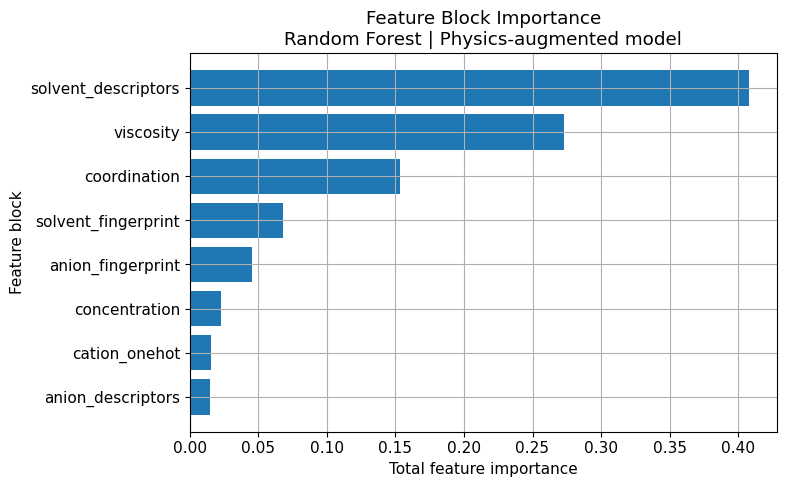

In [23]:
# ==========================================================
# Cell 23 — Feature block importance for the augmented model
# ==========================================================

# We fit the best model on a fixed random split and aggregate feature importances by feature block.
# This helps answer whether viscosity and coordination are actually contributing.

importance_feature_set_name = "Physics-augmented scaled"
importance_fs = feature_sets[importance_feature_set_name]

indices = np.arange(len(data))
train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=RANDOM_STATE)

X_train, X_test, scaler = get_scaled_train_test(
    importance_fs["X_raw"], train_idx, test_idx, importance_fs["scale_indices"]
)

y_train_log = y_log[train_idx]
y_test_raw = y_raw[test_idx]

# Use the best solvent model type if available; otherwise default to Extra Trees.
importance_model = clone(models.get(BEST_MODEL_NAME, models["Extra Trees"]))
importance_model.fit(X_train, y_train_log)

if hasattr(importance_model, "feature_importances_"):
    feature_importance_df = importance_fs["metadata"].copy()
    feature_importance_df["importance"] = importance_model.feature_importances_

    block_importance = (
        feature_importance_df
        .groupby("feature_block")
        .agg(
            total_importance=("importance", "sum"),
            mean_importance=("importance", "mean"),
            n_features=("importance", "size"),
        )
        .reset_index()
        .sort_values("total_importance", ascending=False)
    )

    display(block_importance)
    block_importance.to_csv(METRICS_DIR / "notebook4_feature_block_importance.csv", index=False)

    block_plot = block_importance.sort_values("total_importance")
    plt.figure(figsize=(8, 5))
    plt.barh(block_plot["feature_block"], block_plot["total_importance"])
    plt.xlabel("Total feature importance")
    plt.ylabel("Feature block")
    plt.title(f"Feature Block Importance\n{BEST_MODEL_NAME} | Physics-augmented model")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "notebook4_feature_block_importance.png", dpi=300)
    plt.show()
else:
    print(f"{BEST_MODEL_NAME} does not expose feature_importances_.")

In [26]:
# ==========================================================
# Cell 24 — Final Notebook 4 conclusion table
# ==========================================================

# These conclusions should be edited after checking the actual numbers from your run.

best_summary_row = best_solvent_setting.iloc[0]

notebook4_conclusion = pd.DataFrame([
    {
        "Point addressed": "Mean centering and scaling",
        "What was done": "Continuous descriptors, concentration, viscosity and coordination features were standardized using training-fold StandardScaler.",
        "Evidence generated": "notebook4_scaling_before_after_summary.csv and key scaling summary table",
    },
    {
        "Point addressed": "Actual vs Predicted plots",
        "What was done": "Generated actual vs predicted and residual plots for the best Solvent GroupKFold setting.",
        "Evidence generated": "notebook4_actual_vs_predicted_best_solvent_groupkfold.png and residual plot",
    },
    {
        "Point addressed": "Solvent-wise performance",
        "What was done": "Computed MAE, RMSE, bias, mean actual and mean predicted conductivity for every solvent.",
        "Evidence generated": "notebook4_solvent_wise_error_best_model.csv and worst-solvent plot",
    },
    {
        "Point addressed": "O-based vs N-based solvents",
        "What was done": "Classified solvents using atoms in solvent SMILES and compared family-wise error; family-specific models were explored when enough data existed.",
        "Evidence generated": "notebook4_solvent_family_error_best_model.csv and family-specific summary if generated",
    },
    {
        "Point addressed": "Viscosity and coordination as inputs",
        "What was done": "Compared chemistry-only scaled model against physics-augmented scaled model including viscosity and coordination numbers.",
        "Evidence generated": "notebook4_physics_feature_impact.csv and feature block importance table",
    },
    
])

display(notebook4_conclusion)
notebook4_conclusion.to_csv(METRICS_DIR / "notebook4_conclusion.csv", index=False)

print("Notebook 4 complete.")
print("Best solvent setting:")
print(best_summary_row)

,Point addressed,What was done,Evidence generated
0,Mean centering and scaling,"Continuous descriptors, concentration, viscosi...",notebook4_scaling_before_after_summary.csv and...
1,Actual vs Predicted plots,Generated actual vs predicted and residual plo...,notebook4_actual_vs_predicted_best_solvent_gro...
2,Solvent-wise performance,"Computed MAE, RMSE, bias, mean actual and mean...",notebook4_solvent_wise_error_best_model.csv an...
3,O-based vs N-based solvents,Classified solvents using atoms in solvent SMI...,notebook4_solvent_family_error_best_model.csv ...
4,Viscosity and coordination as inputs,Compared chemistry-only scaled model against p...,notebook4_physics_feature_impact.csv and featu...


Notebook 4 complete.
Best solvent setting:
Feature set            Physics-augmented scaled
Validation                   Solvent GroupKFold
Model                             Random Forest
MAE_mean                               2.885294
MAE_std                                1.522267
RMSE_mean                              5.790948
RMSE_std                               3.570404
R2_mean                                0.559195
R2_std                                 0.241109
Spearman_mean                          0.830222
Spearman_std                           0.059274
PrecisionTop10_mean                    0.628198
PrecisionTop10_std                     0.237959
Name: 0, dtype: object
